In [26]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Loading the clean data set from stage 1
df_raw = pd.read_csv((r"G:\data_analytics_and_genAI\Capstone_project\cleaned_dataset\cleaned_dataset_1.csv"))


In [28]:
df = df_raw.copy()
df = df.drop(['policy_id'], axis=1)  # Dropping the unnamed column

In [29]:
df = df.apply(pd.to_numeric, errors='coerce')

# inspect resulting dtypes
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)
df.dtypes

policy_tenure            float64
age_of_car               float64
age_of_policyholder      float64
population_density         int64
is_esc                     int64
                          ...   
gear_box_6                 int64
steering_type_Manual       int64
steering_type_Power        int64
High_risk_driver_flag      int64
safety_score             float64
Length: 80, dtype: object

In [30]:
import featuretools as ft

# prepare dataframe excluding target
feature_cols = [c for c in df.columns if c != 'is_claim']
df_feat = df[feature_cols].reset_index()  # creates 'index' to use as entity index

# build entityset
es = ft.EntitySet(id="insurance_es")
es.add_dataframe(dataframe_name="claims", dataframe=df_feat, index="index")

# run DFS
feature_matrix, feature_defs = ft.dfs(entityset=es,
                                      target_dataframe_name="claims",
                                      agg_primitives=[],
                                      trans_primitives=['multiply_numeric','add_numeric'],
                                      max_depth=1)

# identify newly generated feature names (exclude original columns)
orig_cols = set(df_feat.columns) - {"index"}
new_candidates = [c for c in feature_matrix.columns if c not in orig_cols]

print("Total DFS feature count:", len(feature_matrix.columns))
print("New candidate names:", new_candidates)

Total DFS feature count: 6241
New candidate names: ['High_risk_driver_flag + is_adjustable_steering', 'High_risk_driver_flag + is_brake_assist', 'High_risk_driver_flag + is_central_locking', 'High_risk_driver_flag + is_day_night_rear_view_mirror', 'High_risk_driver_flag + is_driver_seat_height_adjustable', 'High_risk_driver_flag + is_ecw', 'High_risk_driver_flag + is_esc', 'High_risk_driver_flag + is_front_fog_lights', 'High_risk_driver_flag + is_parking_camera', 'High_risk_driver_flag + is_parking_sensors', 'High_risk_driver_flag + is_power_door_locks', 'High_risk_driver_flag + is_power_steering', 'High_risk_driver_flag + is_rear_window_defogger', 'High_risk_driver_flag + is_rear_window_washer', 'High_risk_driver_flag + is_rear_window_wiper', 'High_risk_driver_flag + is_speed_alert', 'High_risk_driver_flag + is_tpms', 'High_risk_driver_flag + make_2', 'High_risk_driver_flag + make_3', 'High_risk_driver_flag + make_4', 'High_risk_driver_flag + make_5', 'High_risk_driver_flag + model_M1

In [31]:
# compute best_base_corr from base numeric features
num_cols = df.columns.drop('is_claim', errors='ignore')
corrs = df[num_cols].apply(lambda x: x.corr(df['is_claim']))
best_base_corr = corrs.abs().max()

# evaluate DFS features (replace inf/NaN with 0 before corr)
retained = []
for feat in new_candidates:
    if feat not in feature_matrix.columns:
        continue
    s = feature_matrix[feat].replace([np.inf, -np.inf], 0.000001).fillna(0)
    c = s.corr(df['is_claim'])
    if pd.isna(c):
        continue
    if abs(c) > best_base_corr:
        retained.append(feat)

# merge retained features onto df_feat and extend feature list
if retained:
    df_feat = df_feat.merge(feature_matrix[retained], left_on='index', right_index=True, how='left')
extended_feature_cols = feature_cols.copy()
extended_feature_cols.extend(retained)

print("Total Retained DFS features:", len(retained))
print("Retained DFS features:", retained)

print("Extended feature list:", extended_feature_cols)

c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Total Retained DFS features: 3
Retained DFS features: ['area_cluster_C18 + policy_tenure', 'is_speed_alert + policy_tenure', 'is_speed_alert * policy_tenure']
Extended feature list: ['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'area_cluster_C11', 'area_cluster_C12', 'area_cluster_C13', 'area_cluster_C14', 'area_cluster_C15', 'area_cluster_C16', 'area_cluster_C18', 'area_cluster_C19', 'area_cluster_C2', 'area_cluster_C20', 'area_cluster_C21', 'area_cluster_C22', 'area_cluster_C3', 'area_cluster_C4', 'area_cluster_C5', 'area_cluster_C6', 'area_cluster_C7', 'area_cluster_C8', 'area_cluster_C9'

In [32]:
df_feat['is_claim'] = df['is_claim'].values

In [33]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, classification_report
import optuna
from optuna.samplers import TPESampler

# Build X_train2 and X_test2
X_train2, X_test2, y_train, y_test = train_test_split(
    df_feat[extended_feature_cols], 
    df_feat['is_claim'], 
    test_size=0.2, 
    random_state=42
)

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), extended_feature_cols)
    ]
)

# Define objective function for Optuna
def objective(trial):
    max_depth = trial.suggest_int('max_depth', 2, 20)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)
    criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            criterion=criterion,
            random_state=42
        ))
    ])
    
    scores = cross_val_score(
        pipeline, X_train2, y_train, 
        cv=3, 
        scoring='roc_auc'
    )
    
    return scores.mean()

# Run Optuna optimization
sampler = TPESampler(seed=42)
study = optuna.create_study(sampler=sampler, direction='maximize')
study.optimize(objective, n_trials=25, show_progress_bar=True)

# Get best parameters and fit final model
best_params = study.best_params
best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=best_params['max_depth'],
        min_samples_split=best_params['min_samples_split'],
        min_samples_leaf=best_params['min_samples_leaf'],
        criterion=best_params['criterion'],
        random_state=42,
        class_weight="balanced"
    ))
])

best_pipeline.fit(X_train2, y_train)

# Evaluate on test set
y_pred = best_pipeline.predict(X_test2)
y_pred_proba = best_pipeline.predict_proba(X_test2)[:, 1]
test_roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Best Parameters: {best_params}")
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

[I 2026-09-29 17:13:10,907] A new study created in memory with name: no-name-f48ef6f2-b075-4043-ac09-7d3daca34050
Best trial: 0. Best value: 0.598349:   4%|▍         | 1/25 [00:01<00:24,  1.01s/it]

[I 2026-09-29 17:13:11,921] Trial 0 finished with value: 0.5983489322757555 and parameters: {'max_depth': 9, 'min_samples_split': 20, 'min_samples_leaf': 8, 'criterion': 'gini'}. Best is trial 0 with value: 0.5983489322757555.


Best trial: 1. Best value: 0.627044:   8%|▊         | 2/25 [00:01<00:18,  1.21it/s]

[I 2026-09-29 17:13:12,612] Trial 1 finished with value: 0.62704435281746 and parameters: {'max_depth': 4, 'min_samples_split': 3, 'min_samples_leaf': 9, 'criterion': 'entropy'}. Best is trial 1 with value: 0.62704435281746.


Best trial: 1. Best value: 0.627044:  12%|█▏        | 3/25 [00:02<00:15,  1.46it/s]

[I 2026-09-29 17:13:13,128] Trial 2 finished with value: 0.6078374208991318 and parameters: {'max_depth': 2, 'min_samples_split': 20, 'min_samples_leaf': 9, 'criterion': 'gini'}. Best is trial 1 with value: 0.62704435281746.


... (40 outputs left out)

Best trial: 22. Best value: 0.631765:  96%|█████████▌| 24/25 [00:23<00:00,  1.10it/s]

[I 2026-09-29 17:13:34,625] Trial 23 finished with value: 0.613651533574274 and parameters: {'max_depth': 7, 'min_samples_split': 17, 'min_samples_leaf': 9, 'criterion': 'entropy'}. Best is trial 22 with value: 0.6317651804548842.


Best trial: 22. Best value: 0.631765: 100%|██████████| 25/25 [00:24<00:00,  1.02it/s]


[I 2026-09-29 17:13:35,531] Trial 24 finished with value: 0.6315564423287546 and parameters: {'max_depth': 5, 'min_samples_split': 14, 'min_samples_leaf': 7, 'criterion': 'entropy'}. Best is trial 22 with value: 0.6317651804548842.
Best Parameters: {'max_depth': 5, 'min_samples_split': 17, 'min_samples_leaf': 9, 'criterion': 'entropy'}
Best CV ROC-AUC: 0.6318
Test ROC-AUC: 0.6555

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.51      0.66     10176
           1       0.10      0.74      0.17       720

    accuracy                           0.52     10896
   macro avg       0.53      0.62      0.42     10896
weighted avg       0.91      0.52      0.63     10896



In [34]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision_score(y_test, y_pred)

0.09585585585585586

In [35]:
# Split the data into training and testing sets (80-20 split)
# X_train, X_test: feature sets for training and testing
# y_train, y_test: target variable (is_claim) for training and testing
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns=['is_claim']),
    df['is_claim'],
    random_state=42,
    test_size=0.2)

In [36]:
from sklearn.linear_model import LogisticRegression

# Initialize logistic regression model with balanced class weights to handle imbalanced data
# max_iter=1000 ensures convergence for this dataset
lr_baseline = LogisticRegression(class_weight='balanced', max_iter=1000)

# Train the baseline logistic regression model on the training set
lr_baseline.fit(X_train, y_train)

c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [37]:
# prepare features and target using the extended feature set
X = df_feat[extended_feature_cols]
y = df_feat['is_claim']

# define the candidate models to compare
models = {
    'lr_baseline': Pipeline([('preprocessor', preprocessor), ('classifier', lr_baseline)]),
    'best_pipeline': best_pipeline
}

cv_results = {}
for name, model in models.items():
    # evaluate each model using 5-fold CV and ROC-AUC
    scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc', n_jobs=-1)
    cv_results[name] = scores

# collect mean and standard deviation of CV ROC-AUC for each model
comp_df = pd.DataFrame({
    'model': list(cv_results.keys()),
    'mean_auc': [cv_results[m].mean() for m in cv_results],
    'std_auc': [cv_results[m].std() for m in cv_results]
}).sort_values('mean_auc', ascending=False).reset_index(drop=True)

# select the winning model based on highest mean ROC-AUC
winner = comp_df.loc[0, 'model']
chosen_model = models[winner]
chosen_model_name = winner
chosen_model_cv_mean = comp_df.loc[0, 'mean_auc']

print(comp_df)
print(f"Winner: {chosen_model_name} (ROC-AUC={chosen_model_cv_mean:.4f})")

           model  mean_auc   std_auc
0  best_pipeline  0.635788  0.010065
1    lr_baseline  0.605042  0.011449
Winner: best_pipeline (ROC-AUC=0.6358)


In [38]:
import mlflow
import uuid
from datetime import datetime
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

import mlflow.sklearn

# Experiment and unique run naming to avoid collisions
experiment_name = "SafeDrive_Claim_Prediction_AutoML"
mlflow.set_experiment(experiment_name)

# Refit clean pipelines on full X,y to ensure serializable/fitted models for logging

# pipeline for logistic regression
pipeline_lr = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000))])
pipeline_lr.fit(X, y)

# pipeline for decision tree using best_params found earlier (ensure class_weight logged)
dt_clf = DecisionTreeClassifier(
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    min_samples_leaf=best_params['min_samples_leaf'],
    criterion=best_params['criterion'],
    random_state=42,
    class_weight="balanced"
)
pipeline_dt = Pipeline([('preprocessor', preprocessor), ('classifier', dt_clf)])
pipeline_dt.fit(X, y)

# prepare comparison dataframe export (include featuretools_features_added)
comp_export = comp_df.copy()
comp_export['featuretools_features_added'] = 0
ft_added = len(retained) if 'retained' in globals() else 0
comp_export.loc[comp_export['model'] == 'best_pipeline', 'featuretools_features_added'] = ft_added
comp_export.to_csv('experiment_comparison_log_automl.csv.experiment', index=False)

# Log both models to MLflow under the experiment, using unique run names to avoid collisions
for name, model in [('lr_baseline', pipeline_lr), ('best_pipeline', pipeline_dt)]:
    run_name = f"{name}_{datetime.utcnow().strftime('%Y%m%dT%H%M%SZ')}_{uuid.uuid4().hex[:8]}"
    with mlflow.start_run(run_name=run_name):
        # log basic CV metrics from comp_df if available
        row = comp_df[comp_df['model'] == name]
        if not row.empty:
            mlflow.log_metric('roc_auc_mean', float(row['mean_auc'].iloc[0]))
            mlflow.log_metric('roc_auc_std', float(row['std_auc'].iloc[0]))
        # log featuretools param for decision tree run
        if name == 'best_pipeline':
            mlflow.log_param('featuretools_features_added', int(ft_added))
        else:
            mlflow.log_param('featuretools_features_added', 0)
        # log model
        mlflow.sklearn.log_model(model, artifact_path=name)

print("Exported comparison CSV: experiment_comparison_log_automl.csv.experiment")

2026/09/29 17:13:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/29 17:14:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Exported comparison CSV: experiment_comparison_log_automl.csv.experiment


In [39]:
import json
from datetime import datetime

# Create metadata dictionary containing model pipeline information
metadata = {
    'version_tag': version_tag if 'version_tag' in globals() and 'automl' in version_tag else f"automl_{datetime.utcnow():%Y%m%dT%H%M%SZ}",
    'base_feature_columns': feature_cols,  # Original features before featuretools
    'extended_feature_columns': extended_feature_cols,  # Features after adding featuretools-generated ones
    'featuretools_features': retained  # List of retained featuretools-generated features
}

# Export metadata to JSON file for downstream validation and tracking
with open('evidently_metadata_automl.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)

print(f"Written metadata with version_tag={metadata['version_tag']}")

Written metadata with version_tag=automl_20260929T114412Z


Top 10 SHAP features:
area_cluster_C18 + policy_tenure
is_speed_alert + policy_tenure
age_of_car
is_speed_alert * policy_tenure
cylinder_4
engine_type_F8D Petrol Engine
policy_tenure
age_of_policyholder
area_cluster_C8
is_rear_window_wiper

Retained Featuretools features in top 10:
['area_cluster_C18 + policy_tenure', 'is_speed_alert + policy_tenure', 'is_speed_alert * policy_tenure']


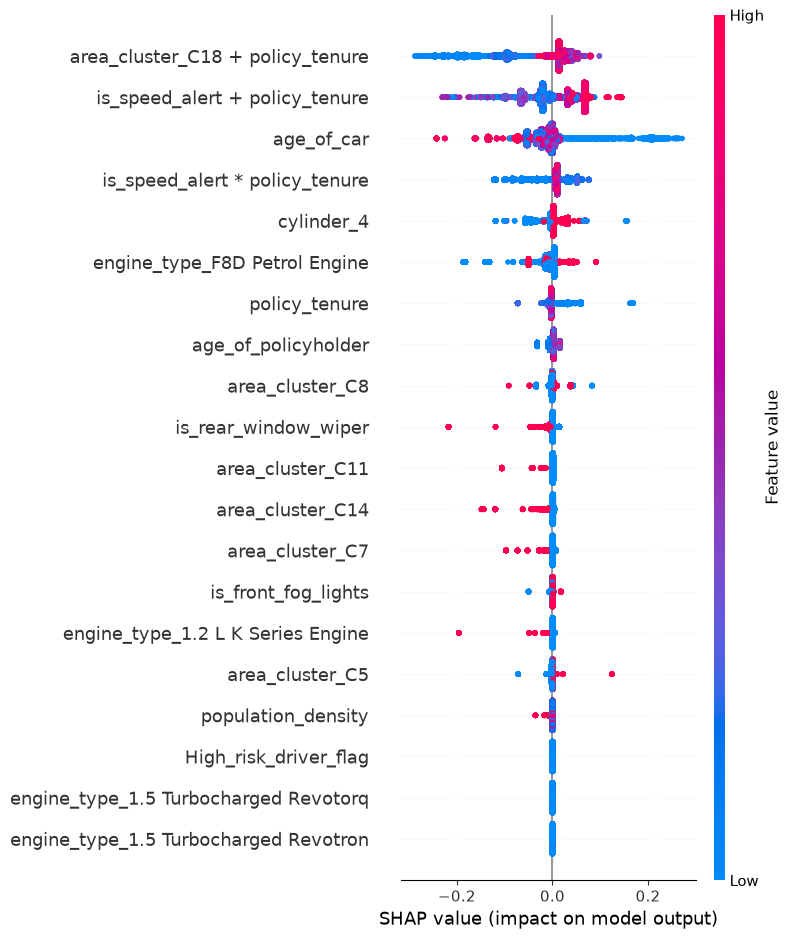

In [40]:
import shap

# Use the trained decision tree classifier and the preprocessor
clf = best_pipeline.named_steps['classifier']
X_shap = X_train2.copy()
X_shap_transformed = preprocessor.transform(X_shap)

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_shap_transformed)

# For binary classification, take the positive class explanation
shap_pos = shap_values[1] if isinstance(shap_values, list) else shap_values

if shap_pos.ndim == 3:
    # select the positive-class explanations for binary classification
    shap_pos = shap_pos[:, :, 1]
elif shap_pos.ndim != 2:
    raise ValueError(f"Unexpected shap_pos ndim: {shap_pos.ndim}")

shap_importance = pd.DataFrame({
    'feature': extended_feature_cols,
    'mean_abs_shap': np.abs(shap_pos).mean(axis=0)
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

# Export SHAP importances
shap_importance.to_csv('shap_feature_importance.csv', index=False)
shap_importance.head(10).to_csv('shap_feature_importance_top10.csv', index=False)

top10_features = shap_importance['feature'].head(10).tolist()
retained_in_top10 = [f for f in retained if f in top10_features]

print("Top 10 SHAP features:")
print("\n".join(top10_features))
print("\nRetained Featuretools features in top 10:")
print(retained_in_top10)

# Summary plot
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_pos, X_shap_transformed, feature_names=extended_feature_cols, show=False)
plt.tight_layout()
plt.savefig('shap_summary_plot_automl.png', dpi=150)
plt.show()

In [41]:
# prepare filesystem utilities for locating previous outputs
import os
import glob

# choose model to produce scores: prefer pipeline_dt (decision tree refit), fallback to best_pipeline
model_for_output = pipeline_dt if 'pipeline_dt' in globals() else best_pipeline

# predict probability for the positive class on full feature set X
predicted_score = model_for_output.predict_proba(X)[:, 1]

# start prediction_output from labels in df_feat and preserve original index if present
prediction_output = df_feat[['is_claim']].copy()
if 'index' in df_feat.columns:
    prediction_output.insert(0, 'index', df_feat['index'])

# attach predicted score
prediction_output['predicted_score'] = predicted_score

# compute percentile thresholds for risk bands (40th, 75th, 90th)
q40, q75, q90 = np.percentile(predicted_score, [40, 75, 90])
thresholds = {'p40': q40, 'p75': q75, 'p90': q90}

# assign categorical risk bands based on thresholds
prediction_output['risk_band'] = pd.cut(
    prediction_output['predicted_score'],
    bins=[-np.inf, q40, q75, q90, np.inf],
    labels=['low', 'medium', 'high', 'very_high'],
    include_lowest=True
)

# summarize counts, percentages, mean predicted score and actual claim rate per band
band_summary = prediction_output.groupby('risk_band', observed=True).agg(
    n=('predicted_score', 'size'),
    pct=('predicted_score', lambda x: len(x) / len(prediction_output) * 100),
    mean_predicted_score=('predicted_score', 'mean'),
    claim_rate=('is_claim', 'mean')
).reset_index()

# print thresholds and band-level summary and simple monotonicity sanity checks
print("Risk-band thresholds (40th / 75th / 90th percentiles of predicted_score):")
print(thresholds)
print("\nRisk-band summary:")
print(band_summary.to_string(index=False))

print("\nMonotonicity sanity check:")
print("Predicted score monotonic:", band_summary['mean_predicted_score'].is_monotonic_increasing)
print("Claim rate monotonic:", band_summary['claim_rate'].is_monotonic_increasing)

# attempt to locate a previous prediction output file for distribution comparison
prev_candidates = set()
if os.path.exists("prediction_output.csv"):
    prev_candidates.add("prediction_output.csv")
prev_candidates.update(glob.glob("*notebook*2*prediction*.csv"))
prev_candidates.update(glob.glob("*prediction_output*notebook*2*.csv"))
prev_candidates.update(glob.glob("*notebook*2*.csv"))

prev_file = sorted(prev_candidates)[0] if prev_candidates else None

if prev_file:
    # load previous predictions and attempt to infer risk bands if absent
    prev_df = pd.read_csv(prev_file)
    if 'risk_band' not in prev_df.columns and 'predicted_score' in prev_df.columns:
        prev_q40, prev_q75, prev_q90 = np.percentile(prev_df['predicted_score'], [40, 75, 90])
        prev_df['risk_band'] = pd.cut(
            prev_df['predicted_score'],
            bins=[-np.inf, prev_q40, prev_q75, prev_q90, np.inf],
            labels=['low', 'medium', 'high', 'very_high'],
            include_lowest=True
        )
    # if previous file has risk bands, compare percentage distributions side-by-side
    if 'risk_band' in prev_df.columns:
        current_dist = prediction_output['risk_band'].value_counts(normalize=True).sort_index() * 100
        previous_dist = prev_df['risk_band'].value_counts(normalize=True).sort_index() * 100
        compare_df = pd.concat(
            [current_dist.rename('current_pct'), previous_dist.rename('previous_pct')],
            axis=1
        ).fillna(0)
        print(f"\nComparing risk-band distribution against {prev_file}:")
        print(compare_df.to_string())
    else:
        print(f"\nFound previous file {prev_file}, but it does not contain risk_band or predicted_score.")
else:
    print("\nNo Notebook 2 candidate prediction output file found for comparison.")

# export current predictions for downstream use
prediction_output.to_csv('prediction_output.csv', index=False)
print("\nExported prediction_output.csv")

Risk-band thresholds (40th / 75th / 90th percentiles of predicted_score):
{'p40': np.float64(0.47110492126265485), 'p75': np.float64(0.5590736384548557), 'p90': np.float64(0.6194405845973859)}

Risk-band summary:
risk_band     n       pct  mean_predicted_score  claim_rate
      low 25062 46.002203              0.325143    0.034435
   medium 16411 30.122981              0.537244    0.075072
     high  9611 17.641336              0.619441    0.101758
very_high  3396  6.233480              0.696366    0.138987

Monotonicity sanity check:
Predicted score monotonic: True
Claim rate monotonic: True

Comparing risk-band distribution against prediction_output.csv:
           current_pct  previous_pct
risk_band                           
low          46.002203     46.002203
medium       30.122981     30.122981
high         17.641336     17.641336
very_high     6.233480      6.233480

Exported prediction_output.csv


<Axes: xlabel='risk_band', ylabel='predicted_score'>

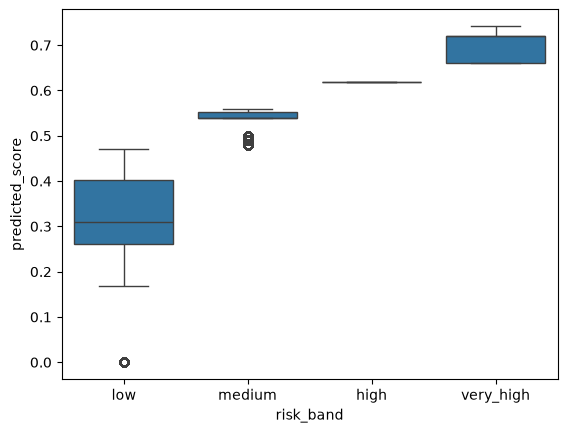

In [42]:
sns.boxplot(data=prediction_output, x='risk_band', y='predicted_score')

In [43]:
prediction_output.head()

,index,is_claim,predicted_score,risk_band
0,0,0,0.402299,low
1,1,0,0.402299,low
2,2,0,0.559074,medium
3,3,0,0.659714,very_high
4,4,0,0.402299,low


In [ ]:
import glob

# Find or use raw dataframe
if 'df_raw' not in globals():
    raw_candidates = sorted(glob.glob('*raw*.csv') + glob.glob('*raw*.parquet'))
    if raw_candidates:
        raw_path = raw_candidates[0]
        raw_df = pd.read_csv(raw_path) if raw_path.lower().endswith('.csv') else pd.read_parquet(raw_path)
    elif 'policy_id' in df.columns:
        raw_df = df.copy()
    else:
        raise ValueError("No raw_df found and no policy_id column available in df to infer raw data.")

if 'policy_id' not in df_raw.columns:
    raise ValueError("df_raw must contain a policy_id column for merging.")

# Attach policy_id to prediction_output if not already present
if 'policy_id' not in prediction_output.columns:
    if 'policy_id' in df.columns:
        prediction_output = prediction_output.merge(
            df[['policy_id']],
            left_on='index',
            right_index=True,
            how='left'
        )
    elif 'policy_id' in df_raw.columns and df_raw.index.equals(prediction_output['index']):
        prediction_output = prediction_output.merge(
            df_raw[['policy_id']],
            left_on='index',
            right_index=True,
            how='left'
        )
    else:
        raise ValueError("Cannot assign policy_id to prediction_output; policy_id missing from df and df_raw index mismatch.")

# Merge scored rows onto full df_raw by policy_id
df_raw_scored = df_raw.merge(
    prediction_output[['policy_id', 'predicted_score', 'risk_band']],
    on='policy_id',
    how='left'
)

df_raw_scored.to_csv('df_raw_scored_by_policy_id.csv', index=False)
df_raw_scored.head()

NameError: name 'raw_df' is not defined

In [48]:
policy_col = "policy_id"

# Preserve policy IDs if present in the test set, otherwise use test index
if policy_col in X_test2.columns:
    policy_ids = X_test2[policy_col].reindex(X_test2.index)
else:
    policy_ids = pd.Series(X_test2.index, index=X_test2.index, name=policy_col)

# Predict classes and probabilities for the test set
y_test_pred_dt = best_pipeline.predict(X_test2)
y_test_prob_dt = best_pipeline.predict_proba(X_test2)[:, 1]

# Assign risk bands based on claim probability thresholds
risk_bands_test = pd.cut(
    y_test_prob_dt,
    bins=[0, 0.40, 0.75, 0.90, 1],
    labels=['low', 'medium', 'high', 'very_high'],
    include_lowest=True
)

# Build the prediction output dataframe
prediction_output = pd.DataFrame({
    policy_col: policy_ids,
    "actual_outcome": y_test.astype(int).values,
    "predicted_class": y_test_pred_dt.astype(int),
    "claim_probability": y_test_prob_dt,
    "risk_level": risk_bands_test
})

# Export predictions to CSV and display the first rows
prediction_output.to_csv("prediction_output.csv", index=False)
display(prediction_output.head())

,policy_id,actual_outcome,predicted_class,claim_probability,risk_level
50332,50332,0,1,0.597293,medium
25831,25831,0,0,0.491538,medium
19185,19185,1,1,0.597293,medium
35935,35935,0,1,0.584650,medium
2982,2982,0,0,0.265579,low


In [49]:
from IPython.display import display, HTML

risk_column = 'risk_level' if 'risk_level' in prediction_output.columns else 'risk_band'

policy_count = prediction_output['policy_id'].nunique()
total_claims = prediction_output['actual_outcome'].sum()
claim_rate = prediction_output['actual_outcome'].mean() * 100
high_risk_count = prediction_output[risk_column].isin(
    ['high', 'very_high']
).sum()

kpi_html = f"""
<div style="display:flex; gap:15px; flex-wrap:wrap;">
    <div style="padding:20px; background:#e8f1ff; border-radius:10px;">
        <h4>Policy Count</h4><h2>{policy_count:,}</h2>
    </div>
    <div style="padding:20px; background:#ffe8e8; border-radius:10px;">
        <h4>Total Claims</h4><h2>{total_claims:,}</h2>
    </div>
    <div style="padding:20px; background:#e8f5e9; border-radius:10px;">
        <h4>Claim Rate</h4><h2>{claim_rate:.2f}%</h2>
    </div>
    <div style="padding:20px; background:#fff3cd; border-radius:10px;">
        <h4>High-Risk Customers</h4><h2>{high_risk_count:,}</h2>
    </div>
</div>
"""

display(HTML(kpi_html))